# PyTorch: тензоры, Autograd и `nn.Module` — классификация сортов фасоли (Dry Bean Dataset)

Практическая работа по **Модулю 06 (Deep Learning), Тема 02**: построение сквозного воспроизводимого пайплайна многоклассовой классификации табличных данных на `PyTorch` — от базовых операций с тензорами, устройствами (`mps` / `cuda` / `cpu`) и автоматического дифференцирования (`Autograd`) до собственного `Dataset`, архитектуры `nn.Module` с регуляризацией, цикла обучения с сохранением лучшего `checkpoint`, верификации `load_state_dict` и честной финальной оценки на отложенной тестовой выборке.

### Объект исследования: UCI Dry Bean Dataset (Koklu & Ozkan, 2020)
Датасет получен компьютерным зрением с высокоскоростной камеры: для каждого зерна фасоли извлечены **16 геометрических и морфометрических признаков** (площадь `Area`, периметр `Perimeter`, длины главной и малой осей, эксцентриситет, выпуклая площадь `ConvexArea`, эквивалентный диаметр, компактность, округлость и факторы формы `ShapeFactor1..4`), по которым требуется распознать один из **7 коммерческих сортов**: `BARBUNYA`, `BOMBAY`, `CALI`, `DERMASON`, `HOROZ`, `SEKER`, `SIRA`.

### Схема инженерного пайплайна
```text
data/dry_bean.csv (13 611 x 17)
   │
   ├─► 1. Аудит качества и дедупликация ДО сплита (-68 дубликатов -> 13 543 уникальных зерна)
   ├─► 2. Стратифицированное разбиение 70% / 15% / 15% (Train: 9 480 | Val: 2 031 | Test: 2 032)
   ├─► 3. StandardScaler (fit строго на Train) + LabelEncoder (0..6) -> Tensor (float32 / int64)
   ├─► 4. DryBeanDataset(Dataset) + DataLoader (train shuffle=True, val/test shuffle=False)
   ├─► 5. DryBeanMLP(nn.Module): 16 -> 64 -> 32 -> 7 (Linear + BatchNorm1d + ReLU + Dropout -> сырые logits)
   ├─► 6. Обучение (CrossEntropyLoss + AdamW + ReduceLROnPlateau) + сохранение лучшего .pt по Val
   └─► 7. Чистый экземпляр + load_state_dict -> сверка logits на Val -> однократная оценка на Test
```

---
## Блок 1. Среда выполнения, фиксация `seed` и базовые механики PyTorch

Перед построением пайплайна зафиксируем генераторы случайных чисел (`Python`, `NumPy`, `PyTorch`) и выберем аппаратный ускоритель по приоритету `cuda -> mps -> cpu`. На Apple Silicon вычисления делегируются графическому бэкенду **Metal Performance Shaders (`mps`)**, который работает с тензорами `float32`.

Затем коротко проверим две фундаментальные механики `PyTorch`, ошибки в которых чаще всего ломают обучение нейросетей:
1. **Согласованность устройств (`device`):** почему операция между тензорами на `cpu` и `mps`/`cuda` немедленно вызывает `RuntimeError` и как явный перенос `.to(device)` решает проблему.
2. **Накопление градиентов в `Autograd`:** почему повторный вызов `loss.backward()` складывает новые производные со старыми в буфере `.grad` и зачем в тренировочном цикле обязателен `optimizer.zero_grad()`.

In [1]:
import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from torch.utils.data import DataLoader, Dataset

# Настройка единого читаемого стиля графиков и таблиц
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)

SEED = 42


def set_seed(seed: int = SEED) -> None:
    """Фиксирует генераторы случайных чисел для воспроизводимости экспериментов."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)


def select_device() -> torch.device:
    """Выбирает доступный аппаратный ускоритель: CUDA -> Apple MPS -> CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


set_seed(SEED)
device = select_device()

env_summary = pd.DataFrame([
    {"Компонент": "PyTorch", "Значение": torch.__version__},
    {"Компонент": "NumPy", "Значение": np.__version__},
    {"Компонент": "Pandas", "Значение": pd.__version__},
    {"Компонент": "Scikit-Learn", "Значение": sklearn.__version__},
    {"Компонент": "Выбранный device", "Значение": str(device)},
    {"Компонент": "MPS доступен", "Значение": str(torch.backends.mps.is_available())},
    {"Компонент": "CUDA доступна", "Значение": str(torch.cuda.is_available())},
])
display(env_summary)

,Компонент,Значение
0,PyTorch,2.15.0
1,NumPy,2.5.4
2,Pandas,3.1.1
3,Scikit-Learn,1.9.1
4,Выбранный device,mps
5,MPS доступен,True
6,CUDA доступна,False


In [2]:
# 1.1. Атрибуты тензора (shape, dtype, device) и конфликт устройств
x_cpu = torch.tensor([[1.5, -0.5, 2.0], [0.2, 1.1, -1.4]], dtype=torch.float32)
w_accel = torch.tensor([[0.4, -0.2], [0.8, 0.5], [-0.3, 0.9]], dtype=torch.float32, device=device)

tensor_info = pd.DataFrame([
    {"Тензор": "x_cpu", "shape": str(tuple(x_cpu.shape)), "dtype": str(x_cpu.dtype), "device": str(x_cpu.device)},
    {"Тензор": "w_accel", "shape": str(tuple(w_accel.shape)), "dtype": str(w_accel.dtype), "device": str(w_accel.device)},
])
display(tensor_info)

# Попытка перемножить тензоры, лежащие в разных адресных пространствах (RAM vs GPU/MPS)
if device.type != "cpu":
    try:
        _ = x_cpu @ w_accel
    except RuntimeError as err:
        print(f"[Ожидаемый RuntimeError при смешивании cpu и {device.type}]:\n  {err}\n")
else:
    print("Активен CPU: оба тензора уже находятся в системной памяти.\n")

# Корректное решение: перенос входного батча на целевое устройство перед операцией
y_accel = x_cpu.to(device) @ w_accel
print(f"После x_cpu.to({device}): shape={tuple(y_accel.shape)}, dtype={y_accel.dtype}, device={y_accel.device}")
print("Результат матричного умножения (перенесён на cpu для печати):\n", y_accel.cpu().numpy().round(4))

,Тензор,shape,dtype,device
0,x_cpu,"(2, 3)",torch.float32,cpu
1,w_accel,"(3, 2)",torch.float32,mps:0


[Ожидаемый RuntimeError при смешивании cpu и mps]:
  Tensor for argument #1 'mat1' is on CPU, but expected it to be on GPU (while checking arguments for mm)



После x_cpu.to(mps): shape=(2, 2), dtype=torch.float32, device=mps:0
Результат матричного умножения (перенесён на cpu для печати):
 [[-0.4   1.25]
 [ 1.38 -0.75]]


In [3]:
# 1.2. Механика Autograd и накопление градиентов без optimizer.zero_grad()
w_demo = torch.tensor([2.0, -1.0], dtype=torch.float32, requires_grad=True)
x_demo = torch.tensor([3.0, 4.0], dtype=torch.float32)
y_target = torch.tensor(5.0, dtype=torch.float32)
optimizer_demo = torch.optim.SGD([w_demo], lr=0.05)

# Аналитическая проверка: L(w) = (w^T x - y)^2  =>  dL/dw = 2 * (w^T x - y) * x
# При w=[2, -1], x=[3, 4], y=5: w^T x - y = (6 - 4) - 5 = -3  =>  dL/dw = 2 * (-3) * [3, 4] = [-18, -24]
analytic_grad = 2.0 * (w_demo.detach() @ x_demo - y_target) * x_demo

# Шаг A: первый прямой и обратный проход
loss_1 = (w_demo @ x_demo - y_target) ** 2
loss_1.backward()
grad_after_first = w_demo.grad.clone()

# Шаг B: повторный backward() БЕЗ обнуления буфера градиентов -> градиенты складываются!
loss_2 = (w_demo @ x_demo - y_target) ** 2
loss_2.backward()
grad_without_zero = w_demo.grad.clone()

# Шаг C: штатный сброс буфера через optimizer.zero_grad() перед новым backward()
optimizer_demo.zero_grad()
loss_3 = (w_demo @ x_demo - y_target) ** 2
loss_3.backward()
grad_after_zero = w_demo.grad.clone()

autograd_df = pd.DataFrame([
    {"Этап": "Аналитический градиент 2*(w^T x - y)*x", "grad[0]": analytic_grad[0].item(), "grad[1]": analytic_grad[1].item()},
    {"Этап": "1-й вызов loss.backward()", "grad[0]": grad_after_first[0].item(), "grad[1]": grad_after_first[1].item()},
    {"Этап": "2-й backward() БЕЗ zero_grad() (удвоение!)", "grad[0]": grad_without_zero[0].item(), "grad[1]": grad_without_zero[1].item()},
    {"Этап": "После optimizer.zero_grad() + backward()", "grad[0]": grad_after_zero[0].item(), "grad[1]": grad_after_zero[1].item()},
])
display(autograd_df)

,Этап,grad[0],grad[1]
0,Аналитический градиент 2*(w^T x - y)*x,-18.0,-24.0
1,1-й вызов loss.backward(),-18.0,-24.0
2,2-й backward() БЕЗ zero_grad() (удвоение!),-36.0,-48.0
3,После optimizer.zero_grad() + backward(),-18.0,-24.0


---
## Блок 2. Данные: EDA, очистка дубликатов, сплит `70/15/15`, `Tensor`, `Dataset` и `DataLoader`

При подготовке табличных данных для нейросети критичны четыре инженерных правила:
1. **Удаление полных дубликатов строго до разбиения:** если одинаковые строки разъедутся между `train` и `val/test`, возникнет утечка данных (`data leakage`) и завышенная оценка обобщающей способности.
2. **Стратифицированное разбиение `train (70%) / val (15%) / test (15%)`:** сохраняет пропорции всех 7 сортов фасоли, включая малочисленный сорт `BOMBAY` (`~3.85%`).
3. **Масштабирование `StandardScaler` строго по `train`:** признаки различаются на **7 порядков величины** (`Area` до `254 616` против `ShapeFactor2 ~ 0.0017`), без стандартизации градиенты по крупным признакам подавят остальные и дестабилизируют шаг оптимизатора.
4. **Строгая типизация тензоров PyTorch:** матрица признаков приводится к `torch.float32` (совместимость со слоями `nn.Linear` и ускорителем `mps`), а целевые индексы классов — к `torch.long` (`int64`, требование `nn.CrossEntropyLoss`).

In [4]:
DATA_PATH = Path("data/dry_bean.csv")
raw_df = pd.read_csv(DATA_PATH)

n_raw = len(raw_df)
n_missing = int(raw_df.isna().sum().sum())
n_exact_dups = int(raw_df.duplicated().sum())
n_feature_dups = int(raw_df.drop(columns=["Class"]).duplicated().sum())
dup_by_class = raw_df.loc[raw_df.duplicated(), "Class"].value_counts().to_dict()

# Удаляем полные дубликаты строк ДО стратифицированного сплита
clean_df = raw_df.drop_duplicates().reset_index(drop=True)
n_clean = len(clean_df)
feature_cols = [col for col in clean_df.columns if col != "Class"]

print(f"Источник данных: {DATA_PATH.as_posix()}")
print(f"Исходный размер таблицы:     {n_raw:,} строк x {raw_df.shape[1]} столбцов ({len(feature_cols)} признаков + Class)")
print(f"Пропущенные значения (NaN):  {n_missing}")
print(f"Полные дубликаты строк:      {n_exact_dups} (распределение по классам: {dup_by_class})")
print(f"Дубликаты только по X:       {n_feature_dups} (противоречивых меток при одинаковых X: {n_feature_dups - n_exact_dups})")
print(f"Размер после очистки:        {n_clean:,} уникальных объектов")

# Сводка по классам до и после дедупликации
raw_counts = raw_df["Class"].value_counts()
clean_counts = clean_df["Class"].value_counts()
class_eda_df = pd.DataFrame({
    "До очистки": raw_counts,
    "Удалено дубл.": raw_counts - clean_counts,
    "После очистки": clean_counts,
    "Доля, %": (clean_counts / n_clean * 100).round(2),
})
display(class_eda_df)

imbalance_ratio = clean_counts.max() / clean_counts.min()
print(f"Кратность дисбаланса классов (DERMASON / BOMBAY): {clean_counts.max()} / {clean_counts.min()} = {imbalance_ratio:.2f}x")

# Таблица масштабов всех 16 признаков
scale_stats_df = clean_df[feature_cols].agg(["min", "median", "mean", "max", "std"]).T
scale_Ratio = scale_stats_df["std"].max() / scale_stats_df["std"].min()
print(f"Отношение max(std) / min(std) по признакам (ConvexArea vs ShapeFactor2): {scale_Ratio:,.0f}x")
display(scale_stats_df.round(5))

Источник данных: data/dry_bean.csv
Исходный размер таблицы:     13,611 строк x 17 столбцов (16 признаков + Class)
Пропущенные значения (NaN):  0
Полные дубликаты строк:      68 (распределение по классам: {'HOROZ': 68})
Дубликаты только по X:       68 (противоречивых меток при одинаковых X: 0)
Размер после очистки:        13,543 уникальных объектов


,До очистки,Удалено дубл.,После очистки,"Доля, %"
Class,,,,
DERMASON,3546,0,3546,26.18
SIRA,2636,0,2636,19.46
SEKER,2027,0,2027,14.97
HOROZ,1928,68,1860,13.73
CALI,1630,0,1630,12.04
BARBUNYA,1322,0,1322,9.76
BOMBAY,522,0,522,3.85


Кратность дисбаланса классов (DERMASON / BOMBAY): 3546 / 522 = 6.79x
Отношение max(std) / min(std) по признакам (ConvexArea vs ShapeFactor2): 50,118,502x


,min,median,mean,max,std
Area,20420.0000,44580.0000,53048.4604,254616.0000,29392.4383
Perimeter,524.7360,793.8960,854.9934,1985.3700,214.7227
MajorAxisLength,183.6012,296.4046,319.8956,738.8601,85.8093
MinorAxisLength,122.5126,192.4911,202.3653,460.1985,45.0516
AspectRation,1.0249,1.5499,1.5811,2.4303,0.2452
Eccentricity,0.2190,0.7640,0.7503,0.9114,0.0919
ConvexArea,20684.0000,45122.0000,53767.9867,263261.0000,29844.2485
EquivDiameter,161.2438,238.2457,253.0341,569.3744,59.3077
Extent,0.5553,0.7599,0.7498,0.8662,0.0489
Solidity,0.9193,0.9883,0.9871,0.9947,0.0046


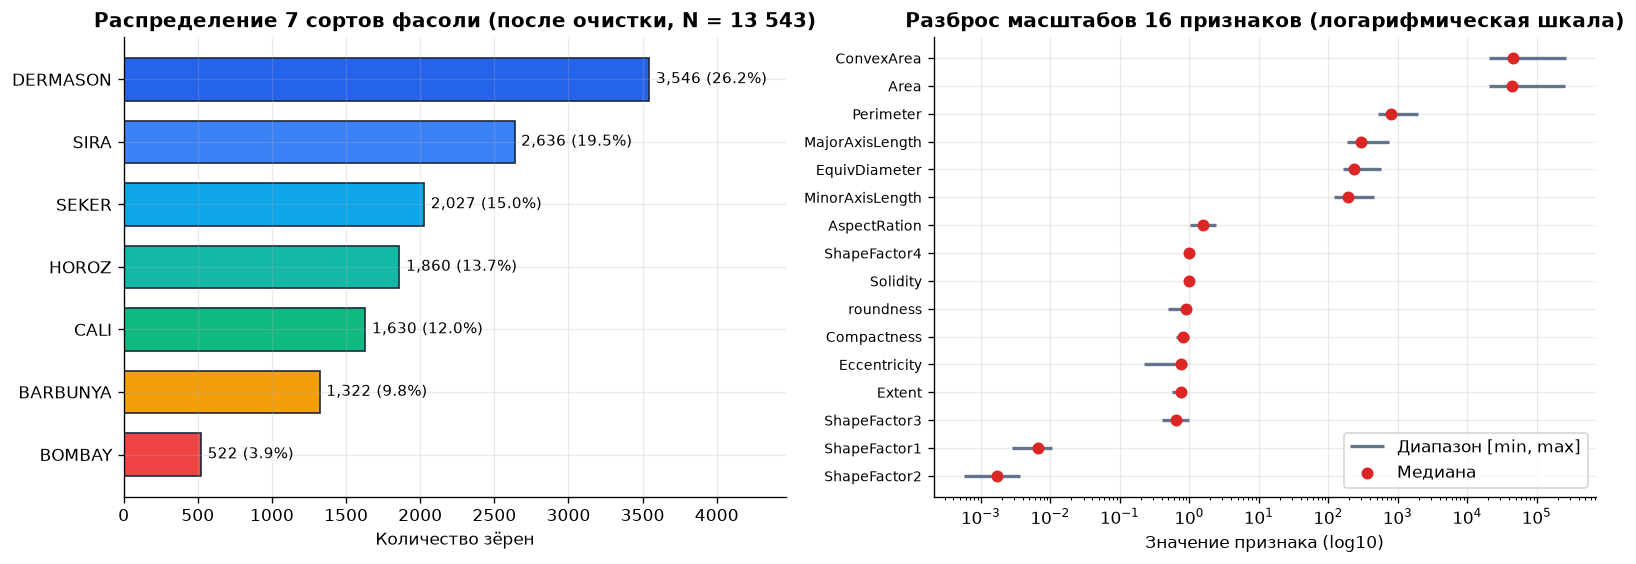

In [5]:
# Визуализация распределения классов и разброса масштабов признаков
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))

# Панель 1: баланс 7 сортов фасоли
ordered_classes = clean_counts.index.tolist()
counts_vals = clean_counts.values
palette = ["#2563eb", "#3b82f6", "#0ea5e9", "#14b8a6", "#10b981", "#f59e0b", "#ef4444"]
bars = ax1.barh(ordered_classes[::-1], counts_vals[::-1], color=palette[::-1], edgecolor="#1e293b", height=0.68)
for bar, cnt in zip(bars, counts_vals[::-1]):
    pct = cnt / n_clean * 100
    ax1.text(bar.get_width() + 45, bar.get_y() + bar.get_height() / 2,
             f"{cnt:,} ({pct:.1f}%)", va="center", fontsize=8.8)
ax1.set_xlim(0, counts_vals.max() * 1.26)
ax1.set_title("Распределение 7 сортов фасоли (после очистки, N = 13 543)", fontweight="bold")
ax1.set_xlabel("Количество зёрен")

# Панель 2: разброс масштабов признаков в логарифмической шкале
stats_sorted = scale_stats_df.sort_values("median", ascending=True)
y_pos = np.arange(len(stats_sorted))
ax2.hlines(y_pos, stats_sorted["min"], stats_sorted["max"], color="#64748b", lw=2.0, label="Диапазон [min, max]")
ax2.scatter(stats_sorted["median"], y_pos, color="#dc2626", s=38, zorder=3, label="Медиана")
ax2.set_xscale("log")
ax2.set_yticks(y_pos)
ax2.set_yticklabels(stats_sorted.index, fontsize=8.5)
ax2.set_title("Разброс масштабов 16 признаков (логарифмическая шкала)", fontweight="bold")
ax2.set_xlabel("Значение признака (log10)")
ax2.legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()

In [6]:
# Кодирование целевых меток (0..6 в алфавитном порядке сортов)
label_encoder = LabelEncoder()
X_all = clean_df[feature_cols].to_numpy(dtype=np.float64)
y_all = label_encoder.fit_transform(clean_df["Class"].to_numpy())
class_names = [str(name) for name in label_encoder.classes_]

# Стратифицированное разбиение 70% Train / 15% Validation / 15% Test
X_train_raw, X_temp_raw, y_train_np, y_temp_np = train_test_split(
    X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED
)
X_val_raw, X_test_raw, y_val_np, y_test_np = train_test_split(
    X_temp_raw, y_temp_np, test_size=0.50, stratify=y_temp_np, random_state=SEED
)

# Проверка сохранения долей всех 7 классов во всех трёх выборках
split_rows = []
for idx, cname in enumerate(class_names):
    tr_c = int((y_train_np == idx).sum())
    va_c = int((y_val_np == idx).sum())
    te_c = int((y_test_np == idx).sum())
    tot_c = int((y_all == idx).sum())
    split_rows.append({
        "Код": idx,
        "Сорт (Class)": cname,
        "Всего": tot_c,
        "Train (70%)": f"{tr_c} ({tr_c / len(y_train_np) * 100:.2f}%)",
        "Val (15%)": f"{va_c} ({va_c / len(y_val_np) * 100:.2f}%)",
        "Test (15%)": f"{te_c} ({te_c / len(y_test_np) * 100:.2f}%)",
    })
display(pd.DataFrame(split_rows))
print(f"Итоговые размеры выборок: Train = {len(y_train_np):,}, Val = {len(y_val_np):,}, Test = {len(y_test_np):,}")

# Стандартизация признаков строго по статистикам обучающей выборки (без утечки из Val/Test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test_raw)

print(
    f"Проверка StandardScaler -> Train mean(|mu|)={np.abs(X_train_scaled.mean(axis=0)).max():.2e}, "
    f"Train std range=[{X_train_scaled.std(axis=0).min():.4f}, {X_train_scaled.std(axis=0).max():.4f}]"
)

,Код,Сорт (Class),Всего,Train (70%),Val (15%),Test (15%)
0,0,BARBUNYA,1322,925 (9.76%),199 (9.80%),198 (9.74%)
1,1,BOMBAY,522,366 (3.86%),78 (3.84%),78 (3.84%)
2,2,CALI,1630,1141 (12.04%),244 (12.01%),245 (12.06%)
3,3,DERMASON,3546,2482 (26.18%),532 (26.19%),532 (26.18%)
4,4,HOROZ,1860,1302 (13.73%),279 (13.74%),279 (13.73%)
5,5,SEKER,2027,1419 (14.97%),304 (14.97%),304 (14.96%)
6,6,SIRA,2636,1845 (19.46%),395 (19.45%),396 (19.49%)


Итоговые размеры выборок: Train = 9,480, Val = 2,031, Test = 2,032
Проверка StandardScaler -> Train mean(|mu|)=1.42e-12, Train std range=[1.0000, 1.0000]


In [7]:
# Преобразование массивов NumPy в тензоры PyTorch с корректными типами данных
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train_np, dtype=torch.long)

X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_t = torch.tensor(y_val_np, dtype=torch.long)

X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test_np, dtype=torch.long)

assert X_train_t.dtype == torch.float32 and y_train_t.dtype == torch.int64


class DryBeanDataset(Dataset):
    """Кастомный табличный Dataset для зёрен фасоли (признаки float32, метки int64)."""

    def __init__(self, features: torch.Tensor, targets: torch.Tensor) -> None:
        if len(features) != len(targets):
            raise ValueError(f"Несовпадение длин X ({len(features)}) и y ({len(targets)})")
        self.features = features
        self.targets = targets

    def __len__(self) -> int:
        return len(self.targets)

    def __getitem__(self, idx: int) -> tuple[torch.Tensor, torch.Tensor]:
        return self.features[idx], self.targets[idx]


train_dataset = DryBeanDataset(X_train_t, y_train_t)
val_dataset = DryBeanDataset(X_val_t, y_val_t)
test_dataset = DryBeanDataset(X_test_t, y_test_t)

# Отдельные DataLoader: перемешивание включено ТОЛЬКО для train
train_gen = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, generator=train_gen)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

# Проверка тензоров, одного элемента Dataset и первого мини-батча DataLoader
tensor_audit = pd.DataFrame([
    {"Выборка": "Train", "X.shape": str(tuple(X_train_t.shape)), "X.dtype": str(X_train_t.dtype),
     "y.shape": str(tuple(y_train_t.shape)), "y.dtype": str(y_train_t.dtype), "Батчей в DataLoader": len(train_loader)},
    {"Выборка": "Validation", "X.shape": str(tuple(X_val_t.shape)), "X.dtype": str(X_val_t.dtype),
     "y.shape": str(tuple(y_val_t.shape)), "y.dtype": str(y_val_t.dtype), "Батчей в DataLoader": len(val_loader)},
    {"Выборка": "Test", "X.shape": str(tuple(X_test_t.shape)), "X.dtype": str(X_test_t.dtype),
     "y.shape": str(tuple(y_test_t.shape)), "y.dtype": str(y_test_t.dtype), "Батчей в DataLoader": len(test_loader)},
])
display(tensor_audit)

sample_x, sample_y = train_dataset[0]
first_xb, first_yb = next(iter(train_loader))
print(
    f"Один объект train_dataset[0]: x.shape={tuple(sample_x.shape)} ({sample_x.dtype}), "
    f"y={sample_y.item()} ({class_names[sample_y.item()]}, {sample_y.dtype})"
)
print(
    f"Первый батч train_loader:     xb.shape={tuple(first_xb.shape)}, yb.shape={tuple(first_yb.shape)}"
)

,Выборка,X.shape,X.dtype,y.shape,y.dtype,Батчей в DataLoader
0,Train,"(9480, 16)",torch.float32,"(9480,)",torch.int64,149
1,Validation,"(2031, 16)",torch.float32,"(2031,)",torch.int64,8
2,Test,"(2032, 16)",torch.float32,"(2032,)",torch.int64,8


Один объект train_dataset[0]: x.shape=(16,) (torch.float32), y=6 (SIRA, torch.int64)
Первый батч train_loader:     xb.shape=(64, 16), yb.shape=(64,)


---
## Блок 3. Архитектура `nn.Module` (`DryBeanMLP`) и подсчёт параметров

Спроектируем компактный многослойный перцептрон `DryBeanMLP` для 16 морфометрических признаков:

```text
Input (B, 16)
  ──► Linear(16 -> 64) ──► BatchNorm1d(64) ──► ReLU ──► Dropout(0.10)
  ──► Linear(64 -> 32) ──► BatchNorm1d(32) ──► ReLU ──► Dropout(0.10)
  ──► Linear(32 -> 7)  ──► сырые logits (B, 7)   [БЕЗ Softmax!]
```

Два архитектурных принципа этой реализации:
1. **Сырые `logits` на выходе `forward`:** функция потерь `nn.CrossEntropyLoss` принимает ненормированные логиты и внутри вычисляет устойчивую композицию `LogSoftmax + NLLLoss` через трюк `LogSumExp`. Добавление `Softmax` внутрь `forward` привело бы к двойному нормированию и затуханию градиентов.
2. **Реальная разница режимов `model.train()` и `model.eval()`:** в режиме `train()` слои `BatchNorm1d` нормируют активации по текущему мини-батчу и обновляют бегущие статистики `running_mean` / `running_var`, а `Dropout(0.10)` случайно гасит 10% нейронов. В режиме `eval()` `Dropout` выключается, а `BatchNorm1d` использует зафиксированные накопленные статистики, делая инференс детерминированным.

In [8]:
MODEL_CONFIG = {
    "in_features": 16,
    "hidden1": 64,
    "hidden2": 32,
    "num_classes": 7,
    "dropout": 0.10,
}


class DryBeanMLP(nn.Module):
    """Полносвязная нейросеть для классификации 7 сортов фасоли (возвращает сырые logits)."""

    def __init__(
        self,
        in_features: int = 16,
        hidden1: int = 64,
        hidden2: int = 32,
        num_classes: int = 7,
        dropout: float = 0.10,
    ) -> None:
        super().__init__()
        self.fc1 = nn.Linear(in_features, hidden1)
        self.bn1 = nn.BatchNorm1d(hidden1)
        self.act1 = nn.ReLU()
        self.drop1 = nn.Dropout(p=dropout)

        self.fc2 = nn.Linear(hidden1, hidden2)
        self.bn2 = nn.BatchNorm1d(hidden2)
        self.act2 = nn.ReLU()
        self.drop2 = nn.Dropout(p=dropout)

        self.fc_out = nn.Linear(hidden2, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.drop1(self.act1(self.bn1(self.fc1(x))))
        x = self.drop2(self.act2(self.bn2(self.fc2(x))))
        logits = self.fc_out(x)  # Сырые логиты формы (batch_size, 7) без Softmax
        return logits


set_seed(SEED)
inspect_model = DryBeanMLP(**MODEL_CONFIG).to(device)
print(inspect_model)

# Послойный аудит обучаемых параметров
param_rows = []
for name, param in inspect_model.named_parameters():
    layer_group = name.split(".")[0]
    param_rows.append({
        "Параметр": name,
        "Слой": layer_group,
        "Форма (shape)": str(tuple(param.shape)),
        "requires_grad": param.requires_grad,
        "Кол-во параметров": param.numel(),
    })
param_df = pd.DataFrame(param_rows)
display(param_df)

total_trainable = sum(p.numel() for p in inspect_model.parameters() if p.requires_grad)
total_buffers = sum(b.numel() for b in inspect_model.buffers())
print(f"Итого обучаемых параметров (requires_grad=True): {total_trainable:,}")
print(f"Необучаемых градиентом буферов BatchNorm1d (входят в state_dict): {total_buffers:,}")

# Практическая проверка разницы между model.train() и model.eval() на одном и том же батче
xb_check = first_xb.to(device)
inspect_model.train()
with torch.no_grad():
    diff_train_mode = (inspect_model(xb_check) - inspect_model(xb_check)).abs().max().item()
inspect_model.eval()
with torch.no_grad():
    diff_eval_mode = (inspect_model(xb_check) - inspect_model(xb_check)).abs().max().item()
print(f"Разброс двух прогонов одного батча -> в train(): max|diff|={diff_train_mode:.6f} (активен Dropout), в eval(): max|diff|={diff_eval_mode:.6f}")

DryBeanMLP(
  (fc1): Linear(in_features=16, out_features=64, bias=True)
  (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (act1): ReLU()
  (drop1): Dropout(p=0.1, inplace=False)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (bn2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (act2): ReLU()
  (drop2): Dropout(p=0.1, inplace=False)
  (fc_out): Linear(in_features=32, out_features=7, bias=True)
)


,Параметр,Слой,Форма (shape),requires_grad,Кол-во параметров
0,fc1.weight,fc1,"(64, 16)",True,1024
1,fc1.bias,fc1,"(64,)",True,64
2,bn1.weight,bn1,"(64,)",True,64
3,bn1.bias,bn1,"(64,)",True,64
4,fc2.weight,fc2,"(32, 64)",True,2048
5,fc2.bias,fc2,"(32,)",True,32
6,bn2.weight,bn2,"(32,)",True,32
7,bn2.bias,bn2,"(32,)",True,32
8,fc_out.weight,fc_out,"(7, 32)",True,224
9,fc_out.bias,fc_out,"(7,)",True,7


Итого обучаемых параметров (requires_grad=True): 3,591
Необучаемых градиентом буферов BatchNorm1d (входят в state_dict): 194


Разброс двух прогонов одного батча -> в train(): max|diff|=1.336596 (активен Dropout), в eval(): max|diff|=0.000000


---
## Блок 4. Обучение: `CrossEntropyLoss`, `AdamW`, `train_one_epoch`, `evaluate` и `checkpoint`

Организуем модульный тренировочный цикл на `60` эпох:
- **Функция потерь:** `nn.CrossEntropyLoss()` (принимает логиты `(B, 7)` и целочисленные метки `(B,)` типа `torch.long`).
- **Оптимизатор и регуляризация:** `AdamW(lr=1e-3, weight_decay=1e-4)` с планировщиком `ReduceLROnPlateau(mode="min", factor=0.5, patience=8)`, уменьшающим шаг при выходе `val_loss` на плато.
- **Точный расчёт средних метрик по эпохе:** в `train_one_epoch` и `evaluate` потери и число верных ответов взвешиваются на реальный размер батча `yb.size(0)`, поскольку последний мини-батч эпохи неполный.
- **Политика чекпоинтинга:** при каждом улучшении `val_acc` (а при равенстве `val_acc` — при снижении `val_loss`) сохраняем словарь с чистыми Python-типами и `state_dict` в `checkpoints/best_dry_bean_mlp.pt`, одновременно фиксируя эталонные логиты на валидации для последующей бит-в-бит проверки `load_state_dict`.

In [9]:
def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    optimizer: torch.optim.Optimizer,
    device: torch.device,
) -> tuple[float, float]:
    """Выполняет одну эпоху обучения модели и возвращает средние (loss, accuracy)."""
    model.train()
    running_loss = 0.0
    correct_preds = 0
    total_samples = 0

    for xb, yb in loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        batch_size = yb.size(0)
        running_loss += loss.item() * batch_size
        correct_preds += (logits.argmax(dim=1) == yb).sum().item()
        total_samples += batch_size

    return running_loss / total_samples, correct_preds / total_samples


def evaluate(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
    return_details: bool = False,
):
    """Оценивает модель в режиме eval() + torch.no_grad() без вычисления градиентов."""
    model.eval()
    running_loss = 0.0
    correct_preds = 0
    total_samples = 0
    logits_batches, preds_batches, targets_batches = [], [], []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(xb)
            loss = criterion(logits, yb)
            preds = logits.argmax(dim=1)

            batch_size = yb.size(0)
            running_loss += loss.item() * batch_size
            correct_preds += (preds == yb).sum().item()
            total_samples += batch_size

            if return_details:
                logits_batches.append(logits.cpu())
                preds_batches.append(preds.cpu())
                targets_batches.append(yb.cpu())

    mean_loss = running_loss / total_samples
    mean_acc = correct_preds / total_samples
    if return_details:
        return (
            mean_loss,
            mean_acc,
            torch.cat(logits_batches, dim=0),
            torch.cat(preds_batches, dim=0),
            torch.cat(targets_batches, dim=0),
        )
    return mean_loss, mean_acc


# Чистая инициализация модели, критерия и оптимизатора перед стартом обучения
set_seed(SEED)
train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(SEED)
)
model = DryBeanMLP(**MODEL_CONFIG).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=8
)

EPOCHS = 60
CHECKPOINT_PATH = Path("checkpoints/best_dry_bean_mlp.pt")
CHECKPOINT_PATH.parent.mkdir(parents=True, exist_ok=True)

history_rows = []
best_val_acc = -1.0
best_val_loss = float("inf")
best_epoch = 0
best_val_logits_snapshot = None
best_val_preds_snapshot = None

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    va_loss, va_acc, va_logits, va_preds, _ = evaluate(
        model, val_loader, criterion, device, return_details=True
    )
    current_lr = optimizer.param_groups[0]["lr"]
    scheduler.step(va_loss)

    is_better = (va_acc > best_val_acc + 1e-12) or (
        abs(va_acc - best_val_acc) <= 1e-12 and va_loss < best_val_loss
    )
    if is_better:
        best_val_acc = float(va_acc)
        best_val_loss = float(va_loss)
        best_epoch = int(epoch)
        best_val_logits_snapshot = va_logits.clone()
        best_val_preds_snapshot = va_preds.clone()

        checkpoint_payload = {
            "epoch": int(epoch),
            "model_state_dict": copy.deepcopy(model.state_dict()),
            "optimizer_state_dict": copy.deepcopy(optimizer.state_dict()),
            "best_val_acc": float(best_val_acc),
            "best_val_loss": float(best_val_loss),
            "class_names": list(class_names),
            "model_config": dict(MODEL_CONFIG),
        }
        torch.save(checkpoint_payload, CHECKPOINT_PATH)

    history_rows.append({
        "epoch": epoch,
        "train_loss": tr_loss,
        "train_acc": tr_acc,
        "val_loss": va_loss,
        "val_acc": va_acc,
        "lr": current_lr,
        "is_best": is_better,
    })

    if epoch == 1 or epoch % 10 == 0 or epoch == EPOCHS:
        print(
            f"Эпоха {epoch:02d}/{EPOCHS} | lr={current_lr:.5f} | "
            f"Train Loss={tr_loss:.4f}, Acc={tr_acc * 100:.2f}% | "
            f"Val Loss={va_loss:.4f}, Acc={va_acc * 100:.2f}%"
        )

history_df = pd.DataFrame(history_rows)
ckpt_kb = CHECKPOINT_PATH.stat().st_size / 1024
print(
    f"\nЛучший чекпоинт сохранён в '{CHECKPOINT_PATH.as_posix()}' ({ckpt_kb:.1f} КБ): "
    f"эпоха {best_epoch}, Val Accuracy = {best_val_acc * 100:.2f}%, Val Loss = {best_val_loss:.4f}"
)

Эпоха 01/60 | lr=0.00100 | Train Loss=0.9176, Acc=79.83% | Val Loss=0.4321, Acc=91.09%


Эпоха 10/60 | lr=0.00100 | Train Loss=0.2496, Acc=91.13% | Val Loss=0.2306, Acc=91.63%


Эпоха 20/60 | lr=0.00100 | Train Loss=0.2342, Acc=91.42% | Val Loss=0.2161, Acc=92.22%


Эпоха 30/60 | lr=0.00050 | Train Loss=0.2162, Acc=92.13% | Val Loss=0.2074, Acc=92.76%


Эпоха 40/60 | lr=0.00050 | Train Loss=0.2119, Acc=92.57% | Val Loss=0.2083, Acc=92.86%


Эпоха 50/60 | lr=0.00025 | Train Loss=0.2087, Acc=92.63% | Val Loss=0.2039, Acc=92.96%


Эпоха 60/60 | lr=0.00025 | Train Loss=0.2075, Acc=92.41% | Val Loss=0.2066, Acc=92.66%

Лучший чекпоинт сохранён в 'checkpoints/best_dry_bean_mlp.pt' (57.0 КБ): эпоха 37, Val Accuracy = 93.35%, Val Loss = 0.2034


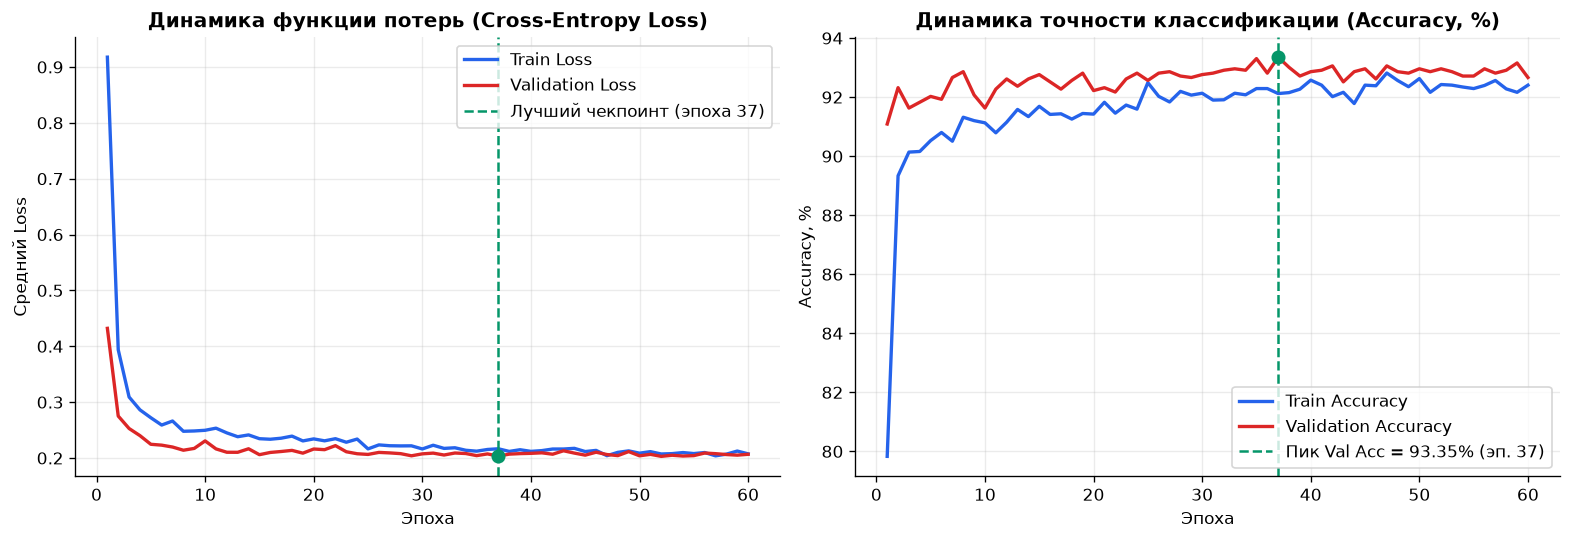

In [10]:
# График динамики потерь (Loss) и точности (Accuracy) на Train / Validation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 4.6))
epochs_arr = history_df["epoch"].to_numpy()

# Панель 1: Cross-Entropy Loss
ax1.plot(epochs_arr, history_df["train_loss"], label="Train Loss", color="#2563eb", lw=2.0)
ax1.plot(epochs_arr, history_df["val_loss"], label="Validation Loss", color="#dc2626", lw=2.0)
ax1.axvline(best_epoch, color="#059669", ls="--", lw=1.5, label=f"Лучший чекпоинт (эпоха {best_epoch})")
ax1.scatter([best_epoch], [best_val_loss], color="#059669", s=55, zorder=5)
ax1.set_title("Динамика функции потерь (Cross-Entropy Loss)", fontweight="bold")
ax1.set_xlabel("Эпоха")
ax1.set_ylabel("Средний Loss")
ax1.legend(frameon=True)

# Панель 2: Accuracy (%)
ax2.plot(epochs_arr, history_df["train_acc"] * 100, label="Train Accuracy", color="#2563eb", lw=2.0)
ax2.plot(epochs_arr, history_df["val_acc"] * 100, label="Validation Accuracy", color="#dc2626", lw=2.0)
ax2.axvline(best_epoch, color="#059669", ls="--", lw=1.5, label=f"Пик Val Acc = {best_val_acc * 100:.2f}% (эп. {best_epoch})")
ax2.scatter([best_epoch], [best_val_acc * 100], color="#059669", s=55, zorder=5)
ax2.set_title("Динамика точности классификации (Accuracy, %)", fontweight="bold")
ax2.set_xlabel("Эпоха")
ax2.set_ylabel("Accuracy, %")
ax2.legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()

---
## Блок 5. Проверка загрузки `state_dict` и финальная честная оценка на `test`

Прежде чем обращаться к отложенной выборке `test_loader`, проверим корректность сериализации чекпоинта:
1. Загружаем файл `checkpoints/best_dry_bean_mlp.pt` в безопасном режиме `torch.load(..., weights_only=True)` (без произвольного `pickle`-кода).
2. Создаём **совершенно новый экземпляр** `loaded_model = DryBeanMLP(...)` со случайными весами, замеряем его базовое качество до загрузки весов, а затем восстанавливаем веса и статистики `BatchNorm1d` вызовом `load_state_dict()`.
3. Сверяем `logits` и предсказанные метки на всём `val_loader` (`2 031` зерно) с эталонным снимком момента сохранения лучшего чекпоинта через `torch.allclose` и `torch.equal`.
4. **Только после 100%-ного совпадения** выполняем однократную финальную оценку `loaded_model` на `test_loader` (`2 032` зерна).

In [11]:
# 1. Безопасная десериализация чекпоинта (weights_only=True)
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
print("Ключи сохранённого чекпоинта:", list(checkpoint.keys()))
print(f"Эпоха чекпоинта: {checkpoint['epoch']} | Конфигурация модели: {checkpoint['model_config']}")

# 2. Создаём новый чистый экземпляр архитектуры и проверяем качество ДО загрузки state_dict
set_seed(999)  # Намеренно другой seed для демонстрации независимой случайной инициализации
loaded_model = DryBeanMLP(**checkpoint["model_config"]).to(device)
untrained_loss, untrained_acc = evaluate(loaded_model, val_loader, criterion, device)

# 3. Загружаем обученные параметры и буферы BatchNorm1d
loaded_model.load_state_dict(checkpoint["model_state_dict"])
reloaded_val_loss, reloaded_val_acc, reloaded_val_logits, reloaded_val_preds, val_targets_cpu = evaluate(
    loaded_model, val_loader, criterion, device, return_details=True
)

# 4. Поэлементная сверка выходов до сохранения и после загрузки
max_logit_diff = (best_val_logits_snapshot - reloaded_val_logits).abs().max().item()
exact_pred_match = bool(torch.equal(best_val_preds_snapshot, reloaded_val_preds))

assert torch.allclose(best_val_logits_snapshot, reloaded_val_logits, atol=1e-6), "Несовпадение logits после load_state_dict!"
assert exact_pred_match, "Несовпадение предсказанных классов после load_state_dict!"

verify_df = pd.DataFrame([
    {"Состояние модели на Validation": "Чистый экземпляр ДО load_state_dict (случайные веса)",
     "Val Loss": round(untrained_loss, 4), "Val Accuracy, %": round(untrained_acc * 100, 2)},
    {"Состояние модели на Validation": f"Эталон при сохранении чекпоинта (эпоха {best_epoch})",
     "Val Loss": round(best_val_loss, 4), "Val Accuracy, %": round(best_val_acc * 100, 2)},
    {"Состояние модели на Validation": "Новый экземпляр ПОСЛЕ load_state_dict()",
     "Val Loss": round(reloaded_val_loss, 4), "Val Accuracy, %": round(reloaded_val_acc * 100, 2)},
])
display(verify_df)
print(f"Проверка пройдена: max |logits_before - logits_after| = {max_logit_diff:.2e}, совпадение предсказаний = {exact_pred_match} (2031/2031)")

Ключи сохранённого чекпоинта: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_acc', 'best_val_loss', 'class_names', 'model_config']
Эпоха чекпоинта: 37 | Конфигурация модели: {'in_features': 16, 'hidden1': 64, 'hidden2': 32, 'num_classes': 7, 'dropout': 0.1}


,Состояние модели на Validation,Val Loss,"Val Accuracy, %"
0,Чистый экземпляр ДО load_state_dict (случайные...,1.9593,7.48
1,Эталон при сохранении чекпоинта (эпоха 37),0.2034,93.35
2,Новый экземпляр ПОСЛЕ load_state_dict(),0.2034,93.35


Проверка пройдена: max |logits_before - logits_after| = 0.00e+00, совпадение предсказаний = True (2031/2031)


,Выборка,Cross-Entropy Loss,"Accuracy, %",Macro F1,Weighted F1
0,"Validation (N = 2,031)",0.2034,93.35,0.9415,0.9336
1,"Test (N = 2,032)",0.2034,92.08,0.9347,0.9209


,Сорт фасоли,Precision,Recall,F1-score,Объектов в Test
0,BARBUNYA,0.9250,0.9343,0.9296,198
1,BOMBAY,1.0000,1.0000,1.0000,78
2,CALI,0.9426,0.9388,0.9407,245
3,DERMASON,0.9237,0.8872,0.9051,532
4,HOROZ,0.9464,0.9498,0.9481,279
5,SEKER,0.9508,0.9539,0.9524,304
6,SIRA,0.8478,0.8864,0.8667,396


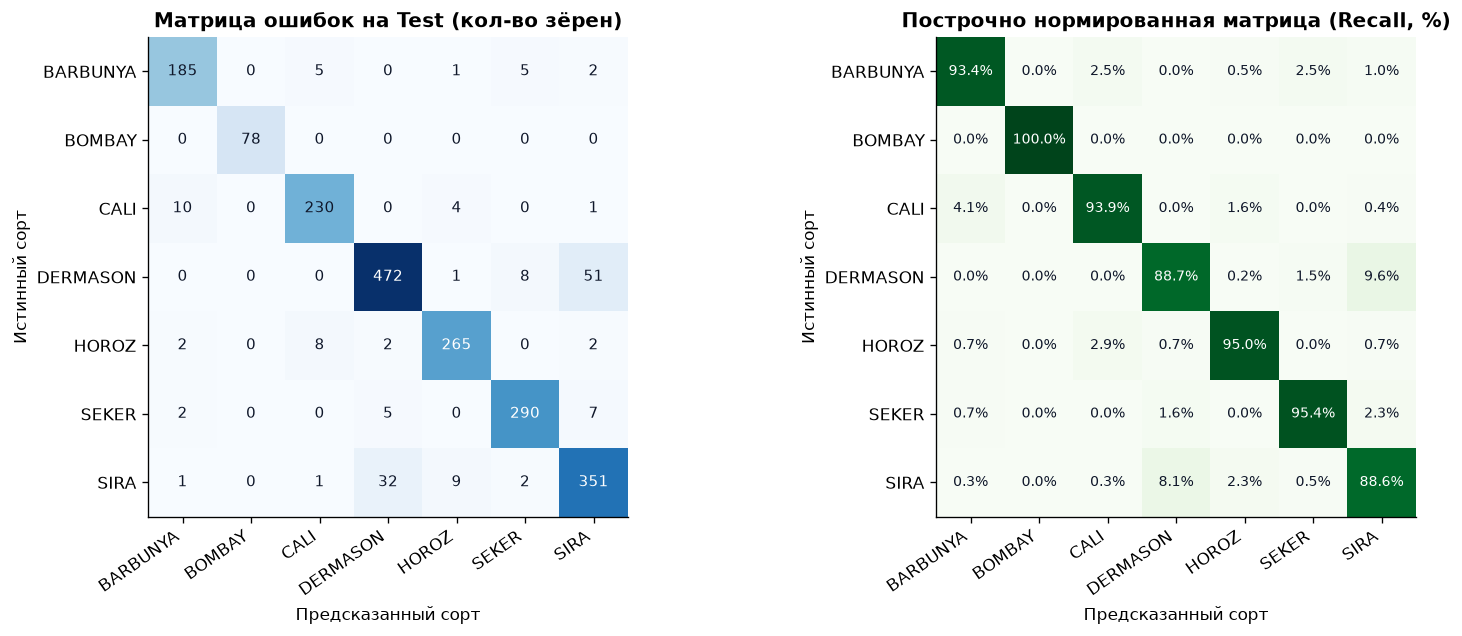

In [12]:
# Однократная финальная оценка восстановленной модели на отложенном test_loader
test_loss, test_acc, test_logits, test_preds, test_targets = evaluate(
    loaded_model, test_loader, criterion, device, return_details=True
)

val_y_np = val_targets_cpu.numpy()
val_p_np = reloaded_val_preds.numpy()
test_y_np = test_targets.numpy()
test_p_np = test_preds.numpy()

final_metrics_df = pd.DataFrame([
    {
        "Выборка": f"Validation (N = {len(val_y_np):,})",
        "Cross-Entropy Loss": round(reloaded_val_loss, 4),
        "Accuracy, %": round(accuracy_score(val_y_np, val_p_np) * 100, 2),
        "Macro F1": round(f1_score(val_y_np, val_p_np, average="macro"), 4),
        "Weighted F1": round(f1_score(val_y_np, val_p_np, average="weighted"), 4),
    },
    {
        "Выборка": f"Test (N = {len(test_y_np):,})",
        "Cross-Entropy Loss": round(test_loss, 4),
        "Accuracy, %": round(accuracy_score(test_y_np, test_p_np) * 100, 2),
        "Macro F1": round(f1_score(test_y_np, test_p_np, average="macro"), 4),
        "Weighted F1": round(f1_score(test_y_np, test_p_np, average="weighted"), 4),
    },
])
display(final_metrics_df)

# Поклассовый отчёт на Test в виде аккуратной таблицы
report_dict = classification_report(
    test_y_np, test_p_np, target_names=checkpoint["class_names"], digits=4, output_dict=True
)
per_class_rows = []
for cname in checkpoint["class_names"]:
    row = report_dict[cname]
    per_class_rows.append({
        "Сорт фасоли": cname,
        "Precision": round(row["precision"], 4),
        "Recall": round(row["recall"], 4),
        "F1-score": round(row["f1-score"], 4),
        "Объектов в Test": int(row["support"]),
    })
display(pd.DataFrame(per_class_rows))

# Визуализация матрицы ошибок (абсолютные числа и построчный Recall %)
cm_counts = confusion_matrix(test_y_np, test_p_np)
cm_recall = cm_counts / cm_counts.sum(axis=1, keepdims=True) * 100.0
cnames = checkpoint["class_names"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.6, 5.4))

im1 = ax1.imshow(cm_counts, cmap="Blues")
ax1.set_title("Матрица ошибок на Test (кол-во зёрен)", fontweight="bold")
ax1.set_xticks(range(len(cnames)), cnames, rotation=35, ha="right")
ax1.set_yticks(range(len(cnames)), cnames)
ax1.set_xlabel("Предсказанный сорт")
ax1.set_ylabel("Истинный сорт")
ax1.grid(False)
for i in range(len(cnames)):
    for j in range(len(cnames)):
        val = cm_counts[i, j]
        color = "white" if val > cm_counts.max() * 0.52 else "#0f172a"
        ax1.text(j, i, f"{val}", ha="center", va="center", color=color, fontsize=8.8)

im2 = ax2.imshow(cm_recall, cmap="Greens", vmin=0, vmax=100)
ax2.set_title("Построчно нормированная матрица (Recall, %)", fontweight="bold")
ax2.set_xticks(range(len(cnames)), cnames, rotation=35, ha="right")
ax2.set_yticks(range(len(cnames)), cnames)
ax2.set_xlabel("Предсказанный сорт")
ax2.set_ylabel("Истинный сорт")
ax2.grid(False)
for i in range(len(cnames)):
    for j in range(len(cnames)):
        pct = cm_recall[i, j]
        color = "white" if pct > 55 else "#0f172a"
        ax2.text(j, i, f"{pct:.1f}%", ha="center", va="center", color=color, fontsize=8.3)

plt.tight_layout()
plt.show()

In [13]:
# Примеры конкретных предсказаний на Test: переход от сырых logits к вероятностям через Softmax на инференсе
test_probs = torch.softmax(test_logits, dim=1)
top2_probs, top2_indices = torch.topk(test_probs, k=2, dim=1)

selected_indices = []
# 1) По одному уверенному верному примеру из каждого из 7 сортов
for cls_idx in range(len(cnames)):
    mask = (test_targets == cls_idx) & (test_preds == cls_idx) & (top2_probs[:, 0] > 0.90)
    idx_candidates = torch.where(mask)[0]
    if len(idx_candidates) > 0:
        selected_indices.append((int(idx_candidates[0].item()), "Верно (уверенно)"))

# 2) Один пограничный верный случай (невысокая уверенность между близкими сортами)
border_mask = (test_targets == test_preds) & (top2_probs[:, 0] < 0.62)
border_candidates = torch.where(border_mask)[0]
if len(border_candidates) > 0:
    selected_indices.append((int(border_candidates[0].item()), "Верно (пограничный)"))

# 3) Две характерные ошибки на морфологически пересекающихся сортах (DERMASON/SIRA и CALI/BARBUNYA)
err_sira_derm = torch.where((test_targets == cnames.index("DERMASON")) & (test_preds == cnames.index("SIRA")))[0]
if len(err_sira_derm) > 0:
    selected_indices.append((int(err_sira_derm[0].item()), "Ошибка (близкие сорта)"))

err_other = torch.where((test_targets != test_preds) & (test_targets != cnames.index("DERMASON")))[0]
if len(err_other) > 0:
    selected_indices.append((int(err_other[0].item()), "Ошибка (пересечение форм)"))

example_rows = []
for sample_idx, note in selected_indices:
    true_cls = cnames[int(test_targets[sample_idx].item())]
    pred_cls = cnames[int(top2_indices[sample_idx, 0].item())]
    p1 = float(top2_probs[sample_idx, 0].item())
    second_cls = cnames[int(top2_indices[sample_idx, 1].item())]
    p2 = float(top2_probs[sample_idx, 1].item())
    example_rows.append({
        "Индекс в Test": sample_idx,
        "Истинный сорт": true_cls,
        "Предсказанный сорт": pred_cls,
        "P(pred)": round(p1, 4),
        "2-й кандидат": second_cls,
        "P(top2)": round(p2, 4),
        "Статус": note,
    })

examples_df = pd.DataFrame(example_rows)
display(examples_df)

,Индекс в Test,Истинный сорт,Предсказанный сорт,P(pred),2-й кандидат,P(top2),Статус
0,18,BARBUNYA,BARBUNYA,0.9999,SEKER,0.0000,Верно (уверенно)
1,22,BOMBAY,BOMBAY,1.0000,HOROZ,0.0000,Верно (уверенно)
2,1,CALI,CALI,0.9778,BARBUNYA,0.0218,Верно (уверенно)
3,0,DERMASON,DERMASON,0.9883,SIRA,0.0101,Верно (уверенно)
4,29,HOROZ,HOROZ,0.9999,SIRA,0.0001,Верно (уверенно)
5,4,SEKER,SEKER,0.9999,DERMASON,0.0001,Верно (уверенно)
6,5,SIRA,SIRA,0.9806,CALI,0.0055,Верно (уверенно)
7,8,SIRA,SIRA,0.5298,DERMASON,0.4420,Верно (пограничный)
8,2,DERMASON,SIRA,0.7257,DERMASON,0.2422,Ошибка (близкие сорта)
9,46,HOROZ,CALI,0.4991,HOROZ,0.3828,Ошибка (пересечение форм)


---
## Итоговые инженерные выводы

1. **Подготовка данных и предотвращение утечек (`Data Leakage`):**
   - В исходном датасете UCI Dry Bean (`13 611` зёрен, `16` геометрических признаков, `0` пропусков) обнаружены **`68` полных дубликатов строк** (все относятся к сорту `HOROZ`). Их удаление **до** разбиения (`13 611 -> 13 543`) исключило попадание идентичных объектов одновременно в `train` и `val/test`.
   - Признаки различаются по стандартному отклонению более чем в **`50 000 000` раз** (`ConvexArea` против `ShapeFactor2`), поэтому стандартизация `StandardScaler` строго по статистикам `train` (`9 480` объектов) обязательна для устойчивой сходимости градиентного спуска.
2. **Архитектура `DryBeanMLP` и дисциплины `PyTorch`:**
   - Компактная сеть `16 -> 64 -> 32 -> 7` (`Linear + BatchNorm1d + ReLU + Dropout(0.10)`) содержит всего **`3 591` обучаемый параметр** (`+ 194` буферных элемента `BatchNorm1d`) и возвращает **сырые `logits` без `Softmax`**, обеспечивая численно устойчивую связку с `nn.CrossEntropyLoss`.
   - Наличие `BatchNorm1d` и `Dropout` делает переключение `model.train()` и `model.eval()` содержательным: в `eval()` прямой проход становится строго детерминированным (`max |diff| = 0.0`).
3. **Сериализация `state_dict` и обобщающая способность:**
   - Лучший чекпоинт достигнут на **37-й эпохе** (`Val Loss = 0.2034`, `Val Accuracy = 93.35%`, `Macro F1 = 0.9415`).
   - Загрузка `checkpoints/best_dry_bean_mlp.pt` в новый чистый экземпляр `DryBeanMLP` через `torch.load(..., weights_only=True)` и `load_state_dict()` дала **нулевое расхождение логитов** на валидации (`max |logits_before - logits_after| = 0.00e+00`, совпадение `2031/2031` предсказаний).
   - На однократно проверенной отложенной выборке `Test` (`2 032` объекта) модель показала **`Test Loss = 0.2034`**, **`Accuracy = 92.08%`**, **`Macro F1 = 0.9347`**, **`Weighted F1 = 0.9209`**.
4. **Структура ошибок по сортам:**
   - Крупнозерновой сорт `BOMBAY` распознаётся безошибочно (`F1 = 1.0000`, `78/78`), высокие показатели достигнуты на `SEKER` (`F1 = 0.9524`), `HOROZ` (`F1 = 0.9481`), `CALI` (`F1 = 0.9407`) и `BARBUNYA` (`F1 = 0.9296`).
   - Основная доля ошибок сосредоточена между морфометрически близкими мелкозерновыми овальными сортами `DERMASON` (`F1 = 0.9051`) и `SIRA` (`F1 = 0.8667`), где пересекаются распределения площади и факторов формы, что полностью согласуется с результатами авторов датасета (Koklu & Ozkan, 2020).